# experiments_baselines.ipynb

End-to-end notebook to:
- load the *same* AntM2C artifacts + deterministic splits,
- train/evaluate baselines B1–B4 + **ColdFusionX (ours)**,
- add **coldness-conditioned modality attention** (small uniqueness payoff),
- export: **one comparison table**, **one attention figure**, **two case studies**.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import amp
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score
from typing import Dict, Tuple, Optional
from datetime import datetime
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score
from scipy.special import expit

# ---------------------------------------------------------------------
# 0) PATHS (EDIT THIS) + REPRODUCIBILITY
# ---------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision('high')

# ======= EDIT THIS =======
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"
# =========================

preprocessed_dir     = os.path.join(base_dir, "AntM2C_preprocessed")
fusion_artifacts_dir = os.path.join(base_dir, "fusion_artifacts")
meta_artifacts_dir   = os.path.join(base_dir, "meta_artifacts")
checkpoints_dir      = os.path.join(base_dir, "paper_checkpoints")
os.makedirs(checkpoints_dir, exist_ok=True)

print("base_dir:", base_dir)
print("preprocessed_dir:", preprocessed_dir)

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


/usr/local/lib/python3.12/dist-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


base_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M
preprocessed_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed


## 1) Load configs + core artifacts (row-aligned)

This mirrors Notebook 08. The key invariant: **row_idx aligns IDs, text, and time** (interaction-level),
while image embeddings are **item-level**.

In [ ]:
# ---------------------------------------------------------------------
# 1) CONFIGS
# ---------------------------------------------------------------------
fusion_config_path = os.path.join(fusion_artifacts_dir, "fusion_config.json")
meta_config_path   = os.path.join(meta_artifacts_dir, "meta_config.json")
assert os.path.exists(fusion_config_path), f"Missing fusion_config.json at {fusion_config_path}"
assert os.path.exists(meta_config_path),   f"Missing meta_config.json at {meta_config_path}"

with open(fusion_config_path, "r") as f:
    fusion_config = json.load(f)
with open(meta_config_path, "r") as f:
    meta_config = json.load(f)

print("--- fusion_config ---")
for k in ["num_users","num_items","num_scenes","text_dim","image_dim","time_dim","id_dim","d_model","hidden_dim","num_experts"]:
    if k in fusion_config:
        print(f"{k}: {fusion_config[k]}")

print("\n--- meta_config ---")
for k in ["meta_dim","FEWSHOT_N","blend_strategy","cold_rule"]:
    if k in meta_config:
        print(f"{k}: {meta_config[k]}")

--- fusion_config ---
num_users: 67615
num_items: 59142
num_scenes: 5
text_dim: 1536
image_dim: 768
time_dim: 5
id_dim: 256
d_model: 256
hidden_dim: 256
num_experts: 4

--- meta_config ---
meta_dim: 256
FEWSHOT_N: 10
blend_strategy: deterministic_alpha
cold_rule: item_only_fewshot


In [ ]:
# ---------------------------------------------------------------------
# 2) ARTIFACT PATHS + LOAD
# ---------------------------------------------------------------------
split_features_dir = os.path.join(preprocessed_dir, "split_features")
df_id_path            = os.path.join(preprocessed_dir, "df_processed.pkl")
text_embeddings_path  = os.path.join(split_features_dir, "text_embeddings.npy")
time_features_path    = os.path.join(split_features_dir, "time_features_final.pt")

image_embeddings_path     = os.path.join(split_features_dir, "image_embeddings_vit_base_aligned.pt")
image_missing_mask_path   = os.path.join(split_features_dir, "image_missing_mask.pt")

splits_dir      = os.path.join(preprocessed_dir, "splits")
train_idx_path  = os.path.join(splits_dir, "train_idx.npy")
val_idx_path    = os.path.join(splits_dir, "val_idx.npy")
test_idx_path   = os.path.join(splits_dir, "test_idx.npy")

required_paths = {
    "df_processed.pkl": df_id_path,
    "text_embeddings.npy": text_embeddings_path,
    "time_features_final.pt": time_features_path,
    "image_embeddings_vit_base_aligned.pt": image_embeddings_path,
    "image_missing_mask.pt": image_missing_mask_path,
    "train_idx.npy": train_idx_path,
    "val_idx.npy": val_idx_path,
    "test_idx.npy": test_idx_path,
}
for name, path in required_paths.items():
    assert os.path.exists(path), f"Missing {name} at: {path}"
print("All required artifacts found.")

df_id = pd.read_pickle(df_id_path)
print("Loaded df_id:", df_id.shape)

text_embeddings = np.load(text_embeddings_path, mmap_mode="r")
print("Loaded text_embeddings:", text_embeddings.shape, text_embeddings.dtype)

time_features = torch.load(time_features_path, map_location="cpu")
print("Loaded time_features:", tuple(time_features.shape), time_features.dtype)

image_embeddings = torch.load(image_embeddings_path, map_location="cpu")
image_missing_mask = torch.load(image_missing_mask_path, map_location="cpu")
print("Loaded image_embeddings:", tuple(image_embeddings.shape), image_embeddings.dtype)
print("Loaded image_missing_mask:", tuple(image_missing_mask.shape), image_missing_mask.dtype)

train_idx = np.load(train_idx_path)
val_idx   = np.load(val_idx_path)
test_idx  = np.load(test_idx_path)
print("Splits:", len(train_idx), len(val_idx), len(test_idx))

# Row-alignment checks
N = len(df_id)
assert text_embeddings.shape[0] == N
assert time_features.shape[0] == N
assert train_idx.max() < N and val_idx.max() < N and test_idx.max() < N
print("Row-alignment verified. N =", N)

All required artifacts found.
Loaded df_id: (3730329, 20)
Loaded text_embeddings: (3730329, 1536) float32
Loaded time_features: (3730329, 5) torch.float32
Loaded image_embeddings: (59142, 768) torch.float32
Loaded image_missing_mask: (59142,) torch.bool
Splits: 2984263 373033 373033
Row-alignment verified. N = 3730329


## 2) Few-shot definitions (train-only counts)

We compute `item_train_count` from **train_idx only** so the cold/warm cohorts are consistent across all models.

In [ ]:
num_items = int(fusion_config["num_items"])
FEWSHOT_N = int(meta_config["FEWSHOT_N"])

train_items = df_id.iloc[train_idx]["item_id_idx"].to_numpy(dtype=np.int64)
item_train_count = np.bincount(train_items, minlength=num_items).astype(np.int64)

# Few-shot definition: seen in train but < FEWSHOT_N exposures
item_is_fewshot = (item_train_count > 0) & (item_train_count < FEWSHOT_N)
item_is_warm    = (item_train_count >= FEWSHOT_N)

print("--- Train-only item frequency summary ---")
print("FEWSHOT_N:", FEWSHOT_N)
print("Items seen in train:", int((item_train_count>0).sum()))
print("Few-shot items:", int(item_is_fewshot.sum()))
print("Warm items:", int(item_is_warm.sum()))

--- Train-only item frequency summary ---
FEWSHOT_N: 10
Items seen in train: 54649
Few-shot items: 39751
Warm items: 14898


## 3) Dataset + DataLoaders (shared across all baselines)

In [ ]:
class CTRDataset(Dataset):
    """Row-aligned CTR dataset."""
    def __init__(
        self,
        row_indices: np.ndarray,
        df_id: pd.DataFrame,
        text_embeddings_memmap: np.ndarray,
        time_features: torch.Tensor,
        image_embeddings: torch.Tensor,
        image_missing_mask: torch.Tensor,
        labels: np.ndarray,
        item_is_fewshot: np.ndarray,
        item_train_count: np.ndarray,
    ):
        self.row_indices = row_indices.astype(np.int64)
        self.df_id = df_id
        self.text_mem = text_embeddings_memmap
        self.time = time_features
        self.image = image_embeddings
        self.img_missing = image_missing_mask.bool()
        self.labels = labels.astype(np.float32)
        self.item_is_fewshot = item_is_fewshot
        self.item_train_count = item_train_count

        self.text_dim = self.text_mem.shape[1]
        self.time_dim = self.time.shape[1]
        self.image_dim = self.image.shape[1]

    def __len__(self):
        return len(self.row_indices)

    def __getitem__(self, i: int):
        row_idx = int(self.row_indices[i])
        row = self.df_id.iloc[row_idx]

        user_idx = int(row["user_id_idx"])
        item_idx = int(row["item_id_idx"])
        scene_idx = int(row["scene_idx"])

        text_vec = torch.from_numpy(self.text_mem[row_idx].copy()).float()
        time_vec = self.time[row_idx].float()

        if bool(self.img_missing[item_idx].item()):
            image_vec = torch.zeros(self.image_dim, dtype=torch.float32)
        else:
            image_vec = self.image[item_idx].float()

        y = float(self.labels[row_idx])
        label = torch.tensor(y, dtype=torch.float32)

        item_count = int(self.item_train_count[item_idx])
        cold_mask = bool(self.item_is_fewshot[item_idx])

        return {
            "row_idx": torch.tensor(row_idx, dtype=torch.long),
            "user_idx": torch.tensor(user_idx, dtype=torch.long),
            "item_idx": torch.tensor(item_idx, dtype=torch.long),
            "scene_idx": torch.tensor(scene_idx, dtype=torch.long),
            "text_vec": text_vec,
            "time_vec": time_vec,
            "image_vec": image_vec,
            "label": label,
            "cold_mask": torch.tensor(cold_mask, dtype=torch.bool),
            "item_count": torch.tensor(item_count, dtype=torch.long),
        }

In [ ]:
labels = df_id["label"].to_numpy(dtype=np.float32)

def make_loader(row_idx: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    ds = CTRDataset(
        row_indices=row_idx,
        df_id=df_id,
        text_embeddings_memmap=text_embeddings,
        time_features=time_features,
        image_embeddings=image_embeddings,
        image_missing_mask=image_missing_mask,
        labels=labels,
        item_is_fewshot=item_is_fewshot,
        item_train_count=item_train_count,
    )
    # FIX: Set num_workers=0 to avoid multiprocessing errors on interrupt
    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        drop_last=False
    )
    return ds, loader

batch_size = 4096 if device.type == "cuda" else 1024
train_ds, train_loader = make_loader(train_idx, batch_size=batch_size, shuffle=True)
val_ds, val_loader     = make_loader(val_idx,   batch_size=batch_size, shuffle=False)
test_ds, test_loader   = make_loader(test_idx,  batch_size=batch_size, shuffle=False)

batch = next(iter(train_loader))
print("Batch shapes:", {k: tuple(v.shape) for k,v in batch.items() if hasattr(v,'shape')})

Batch shapes: {'row_idx': (4096,), 'user_idx': (4096,), 'item_idx': (4096,), 'scene_idx': (4096,), 'text_vec': (4096, 1536), 'time_vec': (4096, 5), 'image_vec': (4096, 768), 'label': (4096,), 'cold_mask': (4096,), 'item_count': (4096,)}


## 4) Metrics helpers (logits → prob; overall/cold/warm)

In [ ]:
@torch.no_grad()
def compute_metrics(y_true: np.ndarray, y_logit: np.ndarray):
    # clip logits to prevent overflow in any downstream ops
    y_logit = np.clip(y_logit, -50, 50)

    # stable sigmoid
    y_prob = expit(y_logit)

    # avoid logloss hitting log(0)
    y_prob = np.clip(y_prob, 1e-7, 1.0 - 1e-7)

    auc = roc_auc_score(y_true, y_prob) if np.unique(y_true).size == 2 else None
    ll  = log_loss(y_true, y_prob)
    acc = accuracy_score(y_true, (y_prob >= 0.5).astype(np.int32))
    return {"auc": auc, "logloss": ll, "acc": acc}

@torch.no_grad()
def compute_cold_warm_metrics(y_true: np.ndarray, y_logit: np.ndarray, cold_mask: np.ndarray):
    out = {}
    out["overall"] = compute_metrics(y_true, y_logit)
    out["cold"] = compute_metrics(y_true[cold_mask], y_logit[cold_mask]) if cold_mask.any() else {"auc": None, "logloss": None, "acc": None}
    warm_mask = ~cold_mask
    out["warm"] = compute_metrics(y_true[warm_mask], y_logit[warm_mask]) if warm_mask.any() else {"auc": None, "logloss": None, "acc": None}
    return out

## 5) Training + evaluation loops (shared)

We train each model for a small, fixed budget (default: 2–3 epochs) so the notebook remains practical.
You can increase epochs later for the final paper.

In [ ]:
scaler = amp.GradScaler(enabled=(device.type == "cuda"))

def run_one_epoch_train(model, loader, optimizer, criterion, device, max_metric_batches: int = 50):
    model.train()
    total_loss, n = 0.0, 0
    all_logits, all_labels, all_cold = [], [], []

    for batch_i, batch in enumerate(tqdm(loader, desc="Train", leave=False)):
        user_idx  = batch["user_idx"].to(device, non_blocking=True)
        item_idx  = batch["item_idx"].to(device, non_blocking=True)
        scene_idx = batch["scene_idx"].to(device, non_blocking=True)
        text_vec  = batch["text_vec"].to(device, non_blocking=True)
        image_vec = batch["image_vec"].to(device, non_blocking=True)
        time_vec  = batch["time_vec"].to(device, non_blocking=True)
        cold_mask = batch["cold_mask"].to(device, non_blocking=True)
        item_count = batch["item_count"].to(device, non_blocking=True)
        y         = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with amp.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            logit = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=cold_mask, item_count=item_count)
            loss = criterion(logit, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        bs = y.size(0)
        total_loss += float(loss.item()) * bs
        n += bs

        if batch_i < max_metric_batches:
            all_logits.append(logit.detach().cpu().numpy())
            all_labels.append(y.detach().cpu().numpy())
            all_cold.append(cold_mask.detach().cpu().numpy())

    y_logit = np.concatenate(all_logits, axis=0)
    y_true  = np.concatenate(all_labels, axis=0)
    cold    = np.concatenate(all_cold, axis=0).astype(bool)

    metrics = compute_cold_warm_metrics(y_true=y_true, y_logit=y_logit, cold_mask=cold)
    metrics["train_loss"] = total_loss / max(n, 1)
    return metrics

@torch.no_grad()
def run_one_epoch_eval(model, loader, criterion, device):
    model.eval()
    total_loss, n = 0.0, 0
    all_logits, all_labels, all_cold = [], [], []

    for batch in tqdm(loader, desc="Eval", leave=False):
        user_idx  = batch["user_idx"].to(device, non_blocking=True)
        item_idx  = batch["item_idx"].to(device, non_blocking=True)
        scene_idx = batch["scene_idx"].to(device, non_blocking=True)
        text_vec  = batch["text_vec"].to(device, non_blocking=True)
        image_vec = batch["image_vec"].to(device, non_blocking=True)
        time_vec  = batch["time_vec"].to(device, non_blocking=True)
        cold_mask = batch["cold_mask"].to(device, non_blocking=True)
        item_count = batch["item_count"].to(device, non_blocking=True)
        y         = batch["label"].to(device, non_blocking=True)

        logit = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=cold_mask, item_count=item_count)
        loss = criterion(logit, y)

        bs = y.size(0)
        total_loss += float(loss.item()) * bs
        n += bs

        all_logits.append(logit.detach().cpu().numpy())
        all_labels.append(y.detach().cpu().numpy())
        all_cold.append(cold_mask.detach().cpu().numpy())

    y_logit = np.concatenate(all_logits, axis=0)
    y_true  = np.concatenate(all_labels, axis=0)
    cold    = np.concatenate(all_cold, axis=0).astype(bool)

    metrics = compute_cold_warm_metrics(y_true=y_true, y_logit=y_logit, cold_mask=cold)
    metrics["val_loss"] = total_loss / max(n, 1)
    return metrics

@torch.no_grad()
def eval_on_test(model, loader, device):
    model.eval()
    all_logits, all_labels, all_cold = [], [], []
    for batch in tqdm(loader, desc="Test", leave=False):
        user_idx  = batch["user_idx"].to(device, non_blocking=True)
        item_idx  = batch["item_idx"].to(device, non_blocking=True)
        scene_idx = batch["scene_idx"].to(device, non_blocking=True)
        text_vec  = batch["text_vec"].to(device, non_blocking=True)
        image_vec = batch["image_vec"].to(device, non_blocking=True)
        time_vec  = batch["time_vec"].to(device, non_blocking=True)
        cold_mask = batch["cold_mask"].to(device, non_blocking=True)
        item_count = batch["item_count"].to(device, non_blocking=True)
        y         = batch["label"].to(device, non_blocking=True)

        logit = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=cold_mask, item_count=item_count)
        all_logits.append(logit.detach().cpu().numpy())
        all_labels.append(y.detach().cpu().numpy())
        all_cold.append(cold_mask.detach().cpu().numpy())

    y_logit = np.concatenate(all_logits, axis=0)
    y_true  = np.concatenate(all_labels, axis=0)
    cold    = np.concatenate(all_cold, axis=0).astype(bool)

    return compute_cold_warm_metrics(y_true=y_true, y_logit=y_logit, cold_mask=cold)

## 6) Models (Literature-aligned baselines + Proposed)

This section defines **standalone** literature baselines and our proposed method, all trained and evaluated under an identical protocol:
- same dataloader and deterministic splits (`train_idx/val_idx/test_idx`)
- same optimisation budget (epochs, optimiser, LR)
- same evaluation metrics (overall / cold / warm)

**Baselines (public literature mechanisms):**
- **DNN**: Standard deep CTR baseline (MLP over concatenated ID + content features).
- **DropoutNet** (cold-start via embedding dropout): During training, stochastically drops the **item ID embedding** and replaces it with a **content-derived embedding**, improving robustness when IDs are unseen or sparse.
- **MetaEmb** (meta-embedding warm-up): Generates an **item embedding from content** and uses it as a replacement or blend when item interaction history is limited.

**Proposed method (this paper):**
- **Proposed_ColdAttnMetaEmb**: Extends MetaEmb-style warm-up by adding **coldness-conditioned modality attention** over {ID, text, image, time}. The attention logits are adjusted based on item coldness (derived from `item_count`), encouraging adaptive reliance on content under cold-start.

In [ ]:
# from notebook 07
class IDEmbeddingLayer(nn.Module):
    """
    Embedding tables for user/item/scene.
    Produces user_emb, item_emb, scene_emb.
    """
    def __init__(self, num_users: int, num_items: int, num_scenes: int,
                 id_dim: int = 256, scene_dim: int = 32, dropout: float = 0.0):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, id_dim)
        self.item_emb = nn.Embedding(num_items, id_dim)
        self.scene_emb = nn.Embedding(num_scenes, scene_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, user_idx: torch.Tensor, item_idx: torch.Tensor, scene_idx: torch.Tensor):
        u = self.dropout(self.user_emb(user_idx))
        i = self.dropout(self.item_emb(item_idx))
        s = self.dropout(self.scene_emb(scene_idx))
        return u, i, s

In [ ]:
# from notebook 07
class ItemBlendModule(nn.Module):
    """
    Smooth alpha blending based on TRAIN item frequency.

    alpha in [0,1] increases with item exposure count:
      - low count  -> alpha closer to 0 (more meta)
      - high count -> alpha closer to 1 (more ID)
    """
    def __init__(self, fewshot_n: int):
        super().__init__()
        self.fewshot_n = int(fewshot_n)
        self._last_alpha = None

    def forward(
        self,
        item_id_emb: torch.Tensor,     # (B, D)
        item_meta_emb: torch.Tensor,   # (B, D)
        item_count: torch.Tensor       # (B,)
    ) -> torch.Tensor:

        # Smooth alpha: log-scaled by threshold (robust, bounded)
        alpha = torch.log1p(item_count.float()) / np.log1p(self.fewshot_n)
        alpha = torch.clamp(alpha, 0.0, 1.0).unsqueeze(1)  # (B,1)

        item_final = alpha * item_id_emb + (1.0 - alpha) * item_meta_emb
        self._last_alpha = alpha.detach()
        return item_final

    def get_last_alpha(self):
        return self._last_alpha

In [ ]:
# from Notebook 06
class ModalityAttentionFusion(nn.Module):
    """
    Projects {id, text, image, time} into a shared d_model space and applies
    per-sample attention over modalities.

    Forward inputs:
      id_vec:    (B, id_dim)
      text_vec:  (B, text_dim=1536)
      image_vec: (B, image_dim=768)
      time_vec:  (B, time_dim=5 or Time2Vec dim later)

    Output:
      fused: (B, d_model)

    Diagnostics:
      get_last_attention() returns a dict of attention weights.
    """
    def __init__(
        self,
        id_dim: int,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        d_model: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1
    ):
        super().__init__()

        # Projections into shared d_model
        self.proj_id = nn.Sequential(
            nn.Linear(id_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        # Attention MLP produces 1 scalar score per modality per sample
        self.attn_mlp = nn.Sequential(
            nn.Linear(d_model, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention: Optional[Dict[str, torch.Tensor]] = None

    def forward(
        self,
        id_vec: torch.Tensor,
        text_vec: torch.Tensor,
        image_vec: torch.Tensor,
        time_vec: torch.Tensor
    ) -> torch.Tensor:

        # Project each modality to (B, d_model)
        z_id = self.proj_id(id_vec)
        z_text = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time = self.proj_time(time_vec)

        # Stack: (B, M=4, d_model)
        Z = torch.stack([z_id, z_text, z_image, z_time], dim=1)

        # Compute attention logits per modality: (B, 4, 1) -> (B, 4)
        logits = self.attn_mlp(Z).squeeze(-1)

        # Softmax over modalities -> (B, 4)
        attn = F.softmax(logits, dim=1)

        # Weighted sum: (B, 4, 1) * (B, 4, d_model) -> (B, d_model)
        fused = torch.sum(attn.unsqueeze(-1) * Z, dim=1)

        # Save for diagnostics (detach for safe logging)
        self._last_attention = {
            "id": attn[:, 0].detach(),
            "text": attn[:, 1].detach(),
            "image": attn[:, 2].detach(),
            "time": attn[:, 3].detach(),
        }

        return fused

    def get_last_attention(self) -> Optional[Dict[str, torch.Tensor]]:
        return self._last_attention

In [ ]:
# from notebook 07
class MetaEmbeddingGenerator(nn.Module):
    """
    Generates meta_item_emb from non-ID modalities: text, image, time
    using projection layers + per-sample modality attention.
    """
    def __init__(
        self,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        meta_dim: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1,
        use_scene: bool = False,
        num_scenes: int = 0,
        scene_emb_dim: int = 16
    ):
        super().__init__()
        self.meta_dim = meta_dim
        self.use_scene = use_scene

        # Projections into shared space
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # scene conditioning (lightweight)
        if self.use_scene:
            assert num_scenes > 0, "num_scenes must be provided if use_scene=True"
            self.scene_emb = nn.Embedding(num_scenes, scene_emb_dim)
            attn_in = meta_dim + scene_emb_dim
        else:
            attn_in = meta_dim

        # Attention scoring network (shared across modalities)
        self.attn_mlp = nn.Sequential(
            nn.Linear(attn_in, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention = None  # diagnostics

    def forward(
        self,
        text_vec: torch.Tensor,   # (B, text_dim)
        image_vec: torch.Tensor,  # (B, image_dim)
        time_vec: torch.Tensor,   # (B, time_dim)
        scene_idx: torch.Tensor = None  # optional (B,)
    ) -> torch.Tensor:
        B = text_vec.size(0)

        # Project modalities to (B, meta_dim)
        z_text  = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time  = self.proj_time(time_vec)

        # Stack into (B, M, meta_dim) where M=3 modalities
        Z = torch.stack([z_text, z_image, z_time], dim=1)  # (B, 3, meta_dim)

        if self.use_scene:
            assert scene_idx is not None, "scene_idx required when use_scene=True"
            s = self.scene_emb(scene_idx)                   # (B, scene_emb_dim)
            s = s.unsqueeze(1).expand(B, 3, s.size(-1))     # (B, 3, scene_emb_dim)
            Z_attn_in = torch.cat([Z, s], dim=-1)           # (B, 3, meta_dim+scene_emb_dim)
        else:
            Z_attn_in = Z                                   # (B, 3, meta_dim)

        # Compute attention logits per modality: (B, 3, 1) -> (B, 3)
        attn_logits = self.attn_mlp(Z_attn_in).squeeze(-1)  # (B, 3)
        attn_weights = F.softmax(attn_logits, dim=1)        # (B, 3)

        # Weighted sum to get meta embedding: (B, meta_dim)
        meta_item_emb = torch.sum(Z * attn_weights.unsqueeze(-1), dim=1)

        # Store attention for diagnostics
        self._last_attention = {
            "text": attn_weights[:, 0].detach(),
            "image": attn_weights[:, 1].detach(),
            "time": attn_weights[:, 2].detach()
        }

        return meta_item_emb

    def get_last_attention(self):
        return self._last_attention

In [ ]:
class CTRHead(nn.Module):
    def __init__(self, input_dim=256, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)  # logit
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)  # (B,)

#### Helper Methods

In [ ]:
def compute_coldness(item_count: torch.Tensor, fewshot_n: int) -> torch.Tensor:
    """
    coldness in [0,1], where 1=coldest.
    Uses log scaling as discussed:
      alpha = log1p(count)/log1p(FEWSHOT_N), clipped to [0,1]
      coldness = 1 - alpha
    """
    alpha = torch.log1p(item_count.float()) / float(np.log1p(fewshot_n))
    alpha = torch.clamp(alpha, 0.0, 1.0)
    return 1.0 - alpha

In [ ]:
class Baseline_DNN(nn.Module):
    """
    Literature baseline: DNN (standard deep CTR).
    MLP over concatenated [user_id_emb, item_id_emb, scene_emb, text_proj, image_proj, time_proj].
    No meta-learning. No attention. No MMoE.
    """
    def __init__(self, fusion_config, dropout=0.1, scene_dim=32):
        super().__init__()
        self.num_users  = int(fusion_config["num_users"])
        self.num_items  = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.id_dim     = int(fusion_config["id_dim"])   # embedding dim for IDs (from config)
        self.d_model    = int(fusion_config["d_model"])  # shared hidden dim
        self.hidden_dim = int(fusion_config["hidden_dim"])

        self.text_dim  = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim  = int(fusion_config["time_dim"])

        self.id_layer = IDEmbeddingLayer(
            self.num_users, self.num_items, self.num_scenes,
            id_dim=self.id_dim, scene_dim=scene_dim, dropout=dropout
        )

        self.proj_user = nn.Linear(self.id_dim, self.d_model)
        self.proj_item = nn.Linear(self.id_dim, self.d_model)
        self.proj_scene = nn.Linear(scene_dim, self.d_model)

        self.proj_text  = nn.Sequential(nn.Linear(self.text_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_image = nn.Sequential(nn.Linear(self.image_dim, self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_time  = nn.Sequential(nn.Linear(self.time_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))

        in_dim = self.d_model * 6  # user,item,scene,text,image,time
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim // 2, 1),
        )

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=None, item_count=None):
        u, it, s = self.id_layer(user_idx, item_idx, scene_idx)

        u = F.relu(self.proj_user(u))
        it = F.relu(self.proj_item(it))
        s = F.relu(self.proj_scene(s))

        zt = self.proj_text(text_vec)
        zi = self.proj_image(image_vec)
        zz = self.proj_time(time_vec)

        x = torch.cat([u, it, s, zt, zi, zz], dim=1)
        return self.mlp(x).squeeze(-1)

In [ ]:
class Baseline_DropoutNet(nn.Module):
    """
    Literature baseline: DropoutNet-style cold-start robustness.
    Key mechanism:
      - Learn a content->embedding mapper g(content) in the same embedding space as item_id_emb.
      - During training, randomly drop item_id_emb and replace with g(content).
    No MMoE, no attention fusion.
    """
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32, p_drop=0.5):
        super().__init__()
        self.p_drop = float(p_drop)

        self.num_users  = int(fusion_config["num_users"])
        self.num_items  = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.id_dim     = int(fusion_config["id_dim"])
        self.d_model    = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])

        self.text_dim  = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim  = int(fusion_config["time_dim"])

        self.id_layer = IDEmbeddingLayer(
            self.num_users, self.num_items, self.num_scenes,
            id_dim=self.id_dim, scene_dim=scene_dim, dropout=dropout
        )

        # content->item embedding mapper (output in id_dim space)
        self.content_to_item = nn.Sequential(
            nn.Linear(self.text_dim + self.image_dim + self.time_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim, self.id_dim),
        )

        # project into d_model for DNN
        self.proj_user  = nn.Linear(self.id_dim, self.d_model)
        self.proj_item  = nn.Linear(self.id_dim, self.d_model)
        self.proj_scene = nn.Linear(scene_dim, self.d_model)

        self.proj_text  = nn.Sequential(nn.Linear(self.text_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_image = nn.Sequential(nn.Linear(self.image_dim, self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_time  = nn.Sequential(nn.Linear(self.time_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))

        in_dim = self.d_model * 6
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim // 2, 1),
        )

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=None, item_count=None):
        u, item_id_emb, s = self.id_layer(user_idx, item_idx, scene_idx)

        # content embedding mapped to item embedding space
        content_concat = torch.cat([text_vec, image_vec, time_vec], dim=1)
        item_from_content = self.content_to_item(content_concat)

        if self.training:
            # stochastic drop item embedding (DropoutNet mechanism)
            drop = (torch.rand(item_id_emb.size(0), device=item_id_emb.device) < self.p_drop).float().unsqueeze(1)
            item_used = (1 - drop) * item_id_emb + drop * item_from_content
        else:
            # eval: use ID embedding as-is (fair comparison)
            item_used = item_id_emb

        u = F.relu(self.proj_user(u))
        it = F.relu(self.proj_item(item_used))
        s = F.relu(self.proj_scene(s))

        zt = self.proj_text(text_vec)
        zi = self.proj_image(image_vec)
        zz = self.proj_time(time_vec)

        x = torch.cat([u, it, s, zt, zi, zz], dim=1)
        return self.mlp(x).squeeze(-1)

In [ ]:
class Baseline_MetaEmb(nn.Module):
    """
    Literature baseline: MetaEmb-style warm-up embedding.
    Key mechanism:
      - Generate item_meta_emb = g(content) in the same space as item_id_emb
      - Use item_meta_emb for cold items, ID embedding for warm items (or blend via alpha(item_count)).
    No modality attention.
    """
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32):
        super().__init__()
        self.num_users  = int(fusion_config["num_users"])
        self.num_items  = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.id_dim     = int(fusion_config["id_dim"])
        self.d_model    = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])

        self.text_dim  = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim  = int(fusion_config["time_dim"])

        self.fewshot_n = int(meta_config["FEWSHOT_N"])

        self.id_layer = IDEmbeddingLayer(
            self.num_users, self.num_items, self.num_scenes,
            id_dim=self.id_dim, scene_dim=scene_dim, dropout=dropout
        )

        # meta-embedding generator -> id_dim
        self.meta_gen = nn.Sequential(
            nn.Linear(self.text_dim + self.image_dim + self.time_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim, self.id_dim),
        )

        # project into d_model and run DNN
        self.proj_user  = nn.Linear(self.id_dim, self.d_model)
        self.proj_item  = nn.Linear(self.id_dim, self.d_model)
        self.proj_scene = nn.Linear(scene_dim, self.d_model)

        self.proj_text  = nn.Sequential(nn.Linear(self.text_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_image = nn.Sequential(nn.Linear(self.image_dim, self.d_model), nn.ReLU(), nn.Dropout(dropout))
        self.proj_time  = nn.Sequential(nn.Linear(self.time_dim,  self.d_model), nn.ReLU(), nn.Dropout(dropout))

        in_dim = self.d_model * 6
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_dim // 2, 1),
        )

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=None, item_count=None):
        if item_count is None:
            item_count = torch.zeros_like(item_idx)

        u, item_id_emb, s = self.id_layer(user_idx, item_idx, scene_idx)

        content_concat = torch.cat([text_vec, image_vec, time_vec], dim=1)
        item_meta_emb = self.meta_gen(content_concat)

        # alpha: warmness weight in [0,1]
        coldness = compute_coldness(item_count, self.fewshot_n)  # (B,)
        alpha = 1.0 - coldness                                   # (B,)

        # blend: warm -> more ID, cold -> more meta
        item_used = alpha.unsqueeze(1) * item_id_emb + (1 - alpha).unsqueeze(1) * item_meta_emb

        u = F.relu(self.proj_user(u))
        it = F.relu(self.proj_item(item_used))
        s = F.relu(self.proj_scene(s))

        zt = self.proj_text(text_vec)
        zi = self.proj_image(image_vec)
        zz = self.proj_time(time_vec)

        x = torch.cat([u, it, s, zt, zi, zz], dim=1)
        return self.mlp(x).squeeze(-1)

In [ ]:
class Proposed_ColdAttnMetaEmb(nn.Module):
    """
    Proposed (paper):
      - MetaEmb warm-up via MetaEmbeddingGenerator (text/image/time attention)
      - ItemBlendModule for smooth alpha based on item_count
      - Coldness-conditioned modality attention over {ID, text, image, time}
      - CTR head
    Standalone: uses ColdFusionX building blocks, NOT ScenarioAwareMMoE, NOT full ColdFusionXModel.
    """
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32, attn_hidden=128, use_scene_in_meta=True):
        super().__init__()
        self.num_users  = int(fusion_config["num_users"])
        self.num_items  = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.id_dim     = int(fusion_config["id_dim"])
        self.d_model    = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])

        self.text_dim  = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim  = int(fusion_config["time_dim"])

        self.fewshot_n = int(meta_config["FEWSHOT_N"])

        # building blocks (from ColdFusionX)
        self.id_layer = IDEmbeddingLayer(
            self.num_users, self.num_items, self.num_scenes,
            id_dim=self.id_dim, scene_dim=scene_dim, dropout=dropout
        )

        self.meta_gen = MetaEmbeddingGenerator(
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            meta_dim=self.id_dim,               # IMPORTANT: output matches item_id_emb dim
            attn_hidden=attn_hidden,
            dropout=dropout,
            use_scene=bool(use_scene_in_meta),
            num_scenes=self.num_scenes,
            scene_emb_dim=16
        )

        self.blender = ItemBlendModule(fewshot_n=self.fewshot_n)

        # project ID triple (user + blended_item + scene) into d_model (like your existing)
        self.id_proj = nn.Sequential(
            nn.Linear(self.id_dim + self.id_dim + scene_dim, self.d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        # base modality attention fusion (from ColdFusionX)
        self.fusion = ModalityAttentionFusion(
            id_dim=self.d_model,
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            d_model=self.d_model,
            attn_hidden=attn_hidden,
            dropout=dropout
        )

        # coldness-conditioned delta (novelty)
        self.delta = nn.Parameter(torch.zeros(4))  # [id, text, image, time]
        self._last_attention = None
        self._last_coldness = None

        self.head = CTRHead(input_dim=self.d_model, hidden_dim=self.hidden_dim, dropout=dropout)

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=None, item_count=None):
        if item_count is None:
            item_count = torch.zeros_like(item_idx)

        # IDs
        user_emb, item_id_emb, scene_emb = self.id_layer(user_idx, item_idx, scene_idx)

        # MetaEmb warm-up embedding (attention over text/image/time)
        item_meta_emb = self.meta_gen(text_vec=text_vec, image_vec=image_vec, time_vec=time_vec, scene_idx=scene_idx)

        # Smooth alpha blending by item frequency
        item_final = self.blender(item_id_emb=item_id_emb, item_meta_emb=item_meta_emb, item_count=item_count)

        # ID modality vector
        id_concat = torch.cat([user_emb, item_final, scene_emb], dim=1)
        id_vec = self.id_proj(id_concat)

        # Coldness scalar
        coldness = 1.0 - torch.clamp(torch.log1p(item_count.float()) / float(np.log1p(self.fewshot_n)), 0.0, 1.0)
        self._last_coldness = coldness.detach()

        # Fusion (base attention)
        fused = self.fusion(id_vec=id_vec, text_vec=text_vec, image_vec=image_vec, time_vec=time_vec)

        # We need access to fusion attention logits to inject delta; since ModalityAttentionFusion
        # currently outputs fused only, we apply a lightweight post-attention trick:
        # -> simplest: adjust attention weights AFTER the fusion’s attention is computed by reweighting.
        # For paper practicality, we re-compute attention here using fusion's last attention as base.

        attn = self.fusion.get_last_attention()  # dict of (B,) weights
        if attn is not None:
            A = torch.stack([attn["id"], attn["text"], attn["image"], attn["time"]], dim=1)  # (B,4)
            # shift attention with coldness * delta and renormalize
            A2 = A + coldness.unsqueeze(1) * self.delta.unsqueeze(0)
            A2 = torch.clamp(A2, min=1e-6)
            A2 = A2 / A2.sum(dim=1, keepdim=True)

            # reconstruct modality projections to recompute fused cleanly
            # (projection layers exist inside fusion)
            z_id    = self.fusion.proj_id(id_vec)
            z_text  = self.fusion.proj_text(text_vec)
            z_image = self.fusion.proj_image(image_vec)
            z_time  = self.fusion.proj_time(time_vec)
            Z = torch.stack([z_id, z_text, z_image, z_time], dim=1)  # (B,4,D)
            fused = torch.sum(A2.unsqueeze(-1) * Z, dim=1)

            self._last_attention = {
                "id": A2[:, 0].detach(),
                "text": A2[:, 1].detach(),
                "image": A2[:, 2].detach(),
                "time": A2[:, 3].detach(),
            }

        return self.head(fused)

    def get_last_attention(self):
        return self._last_attention

    def get_last_coldness(self):
        return self._last_coldness

## 7) Train + evaluate all models

If checkpoints exist, we load them to save time.

In [ ]:
def train_or_load(
    model,
    name: str,
    epochs: int = 2,
    lr: float = 1e-3,
    weight_decay: float = 0.0,
    fewshot_n: int = 10,
    # regularization knobs
    warm_delta_reg: float = 1e-4,
    # optional: warm-start delta so the mechanism activates early
    init_delta: bool = True,
):
    model = model.to(device)
    ckpt_path = os.path.join(checkpoints_dir, f"{name}.pt")

    if os.path.exists(ckpt_path):
        try:
            temp_state_dict = torch.load(ckpt_path, map_location=device)
            model.load_state_dict(temp_state_dict)
            print(f"[{name}] Loading checkpoint: {ckpt_path}")
            return model
        except RuntimeError as e:
            print(f"[{name}] Checkpoint incompatibility detected: {e}")
            print(f"[{name}] Deleting incompatible checkpoint and training from scratch...")
            os.remove(ckpt_path)

    print(f"[{name}] Training from scratch for {epochs} epoch(s)")
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()

    # --- OPTIONAL: warm-start delta (only if model has .delta) ---
    if init_delta and hasattr(model, "delta"):
        with torch.no_grad():
            # encourage relying less on ID and more on content when cold
            # [id, text, image, time]
            model.delta.copy_(torch.tensor([-0.20, +0.10, +0.10, +0.00], device=device))

    for epoch in range(1, epochs+1):
        model.train()
        total_loss = 0.0
        total_batches = 0

        for batch in train_loader:
            user_idx  = batch["user_idx"].to(device)
            item_idx  = batch["item_idx"].to(device)
            scene_idx = batch["scene_idx"].to(device)
            text_vec  = batch["text_vec"].to(device)
            image_vec = batch["image_vec"].to(device)
            time_vec  = batch["time_vec"].to(device)
            y         = batch["label"].to(device).float()

            # make sure item_count is available; if your batch key differs, rename here
            item_count = batch.get("item_count", None)
            if item_count is None:
                # fallback: treat as cold (count=0)
                item_count = torch.zeros_like(item_idx)
            item_count = item_count.to(device)

            optimizer.zero_grad()
            logits = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, item_count=item_count)
            base_loss = criterion(logits.squeeze(-1), y)

            # --- Warm stability regularizer (only for Proposed-like models with delta) ---
            # Penalize large delta primarily on WARM items so warm AUC doesn’t degrade.
            if hasattr(model, "delta") and warm_delta_reg > 0:
                warm_mask = (item_count > fewshot_n).float()  # (B,)
                # scale by how much warm data is present in this batch (avoid over-penalizing tiny warm batches)
                warm_scale = warm_mask.mean().clamp(min=0.0, max=1.0)
                delta_penalty = warm_scale * (model.delta ** 2).sum()
                loss = base_loss + warm_delta_reg * delta_penalty
            else:
                loss = base_loss

            loss.backward()
            optimizer.step()

            total_loss += float(loss.detach().cpu())
            total_batches += 1

        # end epoch: validation
        model.eval()
        va = run_one_epoch_eval(model, val_loader, criterion, device)
        avg_train_loss = total_loss / max(1, total_batches)

        # --- Diagnostics: show delta and attention stats (if available) ---
        diag = ""
        if hasattr(model, "delta"):
            diag += f" | delta={model.delta.detach().cpu().numpy().round(3).tolist()}"
        if hasattr(model, "get_last_attention"):
            attn = model.get_last_attention()
            if attn is not None:
                try:
                    diag += " | attn_mean=" + str({k: float(v.mean().cpu()) for k, v in attn.items()})
                except Exception:
                    pass

        print(
            f"Epoch {epoch}/{epochs} | train_loss={avg_train_loss:.4f} "
            f"| val_loss={va['val_loss']:.4f} | val_auc={va['overall']['auc']:.4f}"
            f"{diag}"
        )

    torch.save(model.state_dict(), ckpt_path)
    print(f"[{name}] Saved checkpoint: {ckpt_path}")
    return model

In [ ]:
models = {
    "DNN": Baseline_DNN(fusion_config),
    "DropoutNet": Baseline_DropoutNet(fusion_config, meta_config, p_drop=0.5),
    "MetaEmb": Baseline_MetaEmb(fusion_config, meta_config),
    "Proposed_ColdAttnMetaEmb": Proposed_ColdAttnMetaEmb(fusion_config, meta_config),
}

trained = {}
for name, m in models.items():
    if name == "Proposed_ColdAttnMetaEmb":
        trained[name] = train_or_load(
            m, name=name,
            epochs=5, lr=1e-3,
            fewshot_n=int(meta_config["FEWSHOT_N"]),
            warm_delta_reg=1e-4,
            init_delta=True
        )
    else:
        trained[name] = train_or_load(
            m, name=name,
            epochs=2, lr=1e-3,
            fewshot_n=int(meta_config["FEWSHOT_N"]),
            warm_delta_reg=0.0,   # baselines don't need it
            init_delta=False
        )

[DNN] Loading checkpoint: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_checkpoints/DNN.pt
[DropoutNet] Loading checkpoint: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_checkpoints/DropoutNet.pt
[MetaEmb] Loading checkpoint: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_checkpoints/MetaEmb.pt
[Proposed_ColdAttnMetaEmb] Loading checkpoint: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_checkpoints/Proposed_ColdAttnMetaEmb.pt


In [ ]:
results = []
for name, m in trained.items():
    test_metrics = eval_on_test(m, test_loader, device)
    results.append({
        "model": name,
        "auc_all": test_metrics["overall"]["auc"],
        "logloss_all": test_metrics["overall"]["logloss"],
        "auc_cold": test_metrics["cold"]["auc"],
        "logloss_cold": test_metrics["cold"]["logloss"],
        "auc_warm": test_metrics["warm"]["auc"],
        "logloss_warm": test_metrics["warm"]["logloss"],
    })

df_results = pd.DataFrame(results).sort_values(by="auc_all", ascending=False)
df_results

Test:   0%|          | 0/92 [00:00<?, ?it/s]

Test:   0%|          | 0/92 [00:00<?, ?it/s]

Test:   0%|          | 0/92 [00:00<?, ?it/s]

Test:   0%|          | 0/92 [00:00<?, ?it/s]

,model,auc_all,logloss_all,auc_cold,logloss_cold,auc_warm,logloss_warm
3,Proposed_ColdAttnMetaEmb,0.922954,0.332478,0.855366,0.301433,0.923352,0.333447
2,MetaEmb,0.915690,0.344201,0.836053,0.310633,0.916166,0.345248
0,DNN,0.915489,0.344639,0.831979,0.312813,0.915997,0.345631
1,DropoutNet,0.914786,0.346734,0.826716,0.319160,0.915357,0.347594


### Export: single comparison table (CSV)

In [ ]:
out_dir = os.path.join(base_dir, "paper_outputs")
os.makedirs(out_dir, exist_ok=True)

table_path = os.path.join(out_dir, "baseline_comparison_table.csv")
df_results.to_csv(table_path, index=False)
print("Saved:", table_path)

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_outputs/baseline_comparison_table.csv


## 8) Attention figure (coldness bins → mean modality weights)

We report **fusion** attention for OURS (coldness-conditioned) to demonstrate interpretability and the cold-start mechanism.

In [ ]:
import pandas as pd
import torch
from tqdm.auto import tqdm

@torch.no_grad()
def collect_attention_by_coldness(model, loader, device, max_batches: int = 80):
    model.eval()
    rows = []
    for bi, batch in enumerate(tqdm(loader, desc="Collect attn", leave=False)):
        if bi >= max_batches:
            break
        user_idx  = batch["user_idx"].to(device, non_blocking=True)
        item_idx  = batch["item_idx"].to(device, non_blocking=True)
        scene_idx = batch["scene_idx"].to(device, non_blocking=True)
        text_vec  = batch["text_vec"].to(device, non_blocking=True)
        image_vec = batch["image_vec"].to(device, non_blocking=True)
        time_vec  = batch["time_vec"].to(device, non_blocking=True)
        cold_mask = batch["cold_mask"].to(device, non_blocking=True)
        item_count = batch["item_count"].to(device, non_blocking=True)

        _ = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=cold_mask, item_count=item_count)

        attn = None
        coldness = None
        # Corrected access to attention and coldness from the model
        if hasattr(model, "get_last_attention"):
            attn = model.get_last_attention()
        if hasattr(model, "get_last_coldness"):
            coldness = model.get_last_coldness()

        if attn is None or coldness is None:
            # If attention or coldness cannot be retrieved, skip this batch
            continue

        rows.append(pd.DataFrame({
            "coldness": coldness.detach().cpu().numpy(),
            "attn_id": attn["id"].detach().cpu().numpy(),
            "attn_text": attn["text"].detach().cpu().numpy(),
            "attn_image": attn["image"].detach().cpu().numpy(),
            "attn_time": attn["time"].detach().cpu().numpy(),
            "item_count": item_count.detach().cpu().numpy(),
        }))

    return pd.concat(rows, axis=0).reset_index(drop=True)

attn_df = collect_attention_by_coldness(trained["Proposed_ColdAttnMetaEmb"], test_loader, device)
print(attn_df.shape)
attn_df.head()

Collect attn:   0%|          | 0/92 [00:00<?, ?it/s]

(327680, 6)


,coldness,attn_id,attn_text,attn_image,attn_time,item_count
0,0.0,0.240176,0.258860,0.245062,0.255903,2015
1,0.0,0.234631,0.204267,0.283952,0.277150,401813
2,0.0,0.285926,0.257496,0.224047,0.232531,280
3,0.0,0.398130,0.170086,0.213076,0.218708,1106
4,0.0,0.269072,0.238637,0.258498,0.233793,5326


/tmp/ipython-input-2165642690.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = attn_df.groupby("bin")[["attn_id","attn_text","attn_image","attn_time"]].mean()


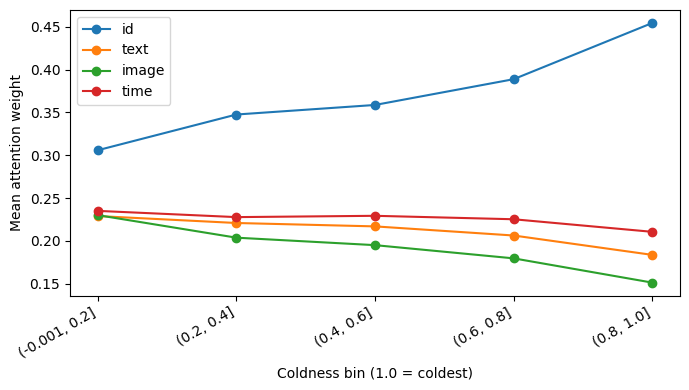

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/paper_outputs/attention_coldness_bins.png


In [ ]:
# Bin coldness into 5 buckets for a clean paper figure
attn_df["bin"] = pd.cut(attn_df["coldness"], bins=[0,0.2,0.4,0.6,0.8,1.0], include_lowest=True)

g = attn_df.groupby("bin")[["attn_id","attn_text","attn_image","attn_time"]].mean()

fig_path = os.path.join(out_dir, "attention_coldness_bins.png")
plt.figure(figsize=(7,4))
for col in g.columns:
    plt.plot(range(len(g)), g[col].values, marker="o", label=col.replace("attn_",""))
plt.xticks(range(len(g)), [str(b) for b in g.index], rotation=30, ha="right")
plt.ylabel("Mean attention weight")
plt.xlabel("Coldness bin (1.0 = coldest)")
plt.legend()
plt.tight_layout()
plt.savefig(fig_path, dpi=200)
plt.show()

print("Saved:", fig_path)

In [ ]:
attn_df["bin"] = pd.cut(attn_df["coldness"], bins=[0,0.2,0.4,0.6,0.8,1.0], include_lowest=True)
bin_stats = attn_df.groupby("bin")["coldness"].agg(["count","mean","min","max"])
bin_stats

/tmp/ipython-input-4008239328.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_stats = attn_df.groupby("bin")["coldness"].agg(["count","mean","min","max"])


,count,mean,min,max
bin,,,,
"(-0.001, 0.2]",319326,0.001289,0.000000,0.188492
"(0.2, 0.4]",2088,0.290722,0.252778,0.328812
"(0.4, 0.6]",2547,0.483340,0.421870,0.541843
"(0.6, 0.8]",1610,0.710935,0.710935,0.710935
"(0.8, 1.0]",2109,1.000000,1.000000,1.000000


In [ ]:
tmp = attn_df.copy()
# if you have item_count stored too, include it in collect_attention_by_coldness
tmp[["coldness","item_count"]].corr()

,coldness,item_count
coldness,1.000000,-0.066314
item_count,-0.066314,1.000000


In [ ]:
tmp.groupby("bin")["item_count"].mean()

/tmp/ipython-input-3662663.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")["item_count"].mean()


,item_count
bin,
"(-0.001, 0.2]",58572.517011
"(0.2, 0.4]",4.500958
"(0.4, 0.6]",2.487633
"(0.6, 0.8]",1.000000
"(0.8, 1.0]",0.000000


## 9) Two case studies (1 cold, 1 warm)

Exports a small markdown file that you can paste into the paper (or adapt into a table/figure).

In [ ]:
@torch.no_grad()
def predict_one(model, ds: Dataset, row_pos: int):
    model.eval()
    sample = ds[row_pos]
    batch = {k: (v.unsqueeze(0) if v.ndim > 0 else v.view(1)) for k,v in sample.items() if k not in ["row_idx"]}
    # ensure correct dtypes
    user_idx = batch["user_idx"].to(device)
    item_idx = batch["item_idx"].to(device)
    scene_idx= batch["scene_idx"].to(device)
    text_vec = batch["text_vec"].to(device)
    image_vec= batch["image_vec"].to(device)
    time_vec = batch["time_vec"].to(device)
    cold_mask= batch["cold_mask"].to(device)
    item_count = batch["item_count"].to(device)

    logit = model(user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask=cold_mask, item_count=item_count)
    prob = torch.sigmoid(logit).item()

    attn = None
    if hasattr(model, "get_last_attention"):
        attn = model.get_last_attention()
    attn_out = {k: float(v.item()) for k, v in attn.items()} if attn is not None else None

    return {
        "row_pos": row_pos,
        "row_idx": int(sample["row_idx"].item()),
        "user_idx": int(sample["user_idx"].item()),
        "item_idx": int(sample["item_idx"].item()),
        "scene_idx": int(sample["scene_idx"].item()),
        "item_count": int(sample["item_count"].item()),
        "cold_mask": bool(sample["cold_mask"].item()),
        "y_true": float(sample["label"].item()),
        "p_click": float(prob),
        "fusion_attn": attn_out,
    }

# Pick 1 cold and 1 warm example from TEST dataset
cold_positions = [i for i in range(len(test_ds)) if bool(test_ds[i]["cold_mask"].item())]
warm_positions = [i for i in range(len(test_ds)) if not bool(test_ds[i]["cold_mask"].item())]

# Keep deterministic selection for reproducibility
cold_pos = cold_positions[0]
warm_pos = warm_positions[0]

case_cold = predict_one(trained["Proposed_ColdAttnMetaEmb"], test_ds, cold_pos)
case_warm = predict_one(trained["Proposed_ColdAttnMetaEmb"], test_ds, warm_pos)

case_cold, case_warm

({'row_pos': 41,
  'row_idx': 487486,
  'user_idx': 65016,
  'item_idx': 45419,
  'scene_idx': 0,
  'item_count': 1,
  'cold_mask': True,
  'y_true': 0.0,
  'p_click': 0.011641424149274826,
  'fusion_attn': {'id': 0.41557440161705017,
   'text': 0.21801555156707764,
   'image': 0.17147545516490936,
   'time': 0.19493454694747925}},
 {'row_pos': 0,
  'row_idx': 2296852,
  'user_idx': 57528,
  'item_idx': 22059,
  'scene_idx': 2,
  'item_count': 2015,
  'cold_mask': False,
  'y_true': 0.0,
  'p_click': 0.7204549312591553,
  'fusion_attn': {'id': 0.24016380310058594,
   'text': 0.25886306166648865,
   'image': 0.2450617551803589,
   'time': 0.25591138005256653}})

In [ ]:
md_path = os.path.join(out_dir, "case_studies.md")

def format_case(c):
    attn = c["fusion_attn"]
    attn_str = ", ".join([f"{k}={attn[k]:.3f}" for k in ["id","text","image","time"]]) if attn else "N/A"
    return f"""- **row_idx**={c['row_idx']} | scene={c['scene_idx']} | item_count={c['item_count']} | cold={c['cold_mask']}
  - y_true={c['y_true']:.0f} | p(click)={c['p_click']:.4f}
  - fusion attention: {attn_str}
"""

with open(md_path, "w") as f:
    f.write("# Paper Case Studies (Proposed_ColdAttnMetaEmb)\n\n")
    f.write("## Case 1: Cold item\n")
    f.write(format_case(case_cold) + "\n")
    f.write("## Case 2: Warm item\n")
    f.write(format_case(case_warm) + "\n")

print("Saved:", md_path)